# Metasurface: metalens unit cell library
Silicon nanopillars on glass at 1550 nm. Sweep pillar radius to build a transmission phase library, then lay out a hyperbolic metalens from it

## Setup

using simulation folder runs/r0.080
using simulation folder runs/r0.124
using simulation folder runs/r0.168
using simulation folder runs/r0.212
using simulation folder runs/r0.256
using simulation folder runs/r0.300


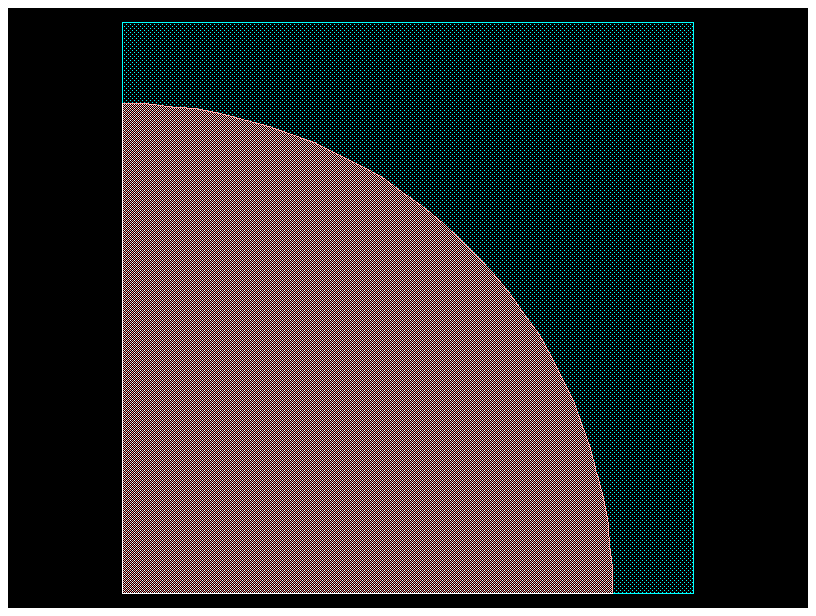

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# simulation folder
root = "runs"

# dims [um]
# length units are arbitrary so long as they're consistent
P = 0.7  # periodicity, subwavelength in substrate (P < wavelength / n_sub) so no diffraction
h = 1.0  # pillar height
radii = np.linspace(0.08, 0.3, 6)  # pillar radii to sweep

# refractive indices
n_si = 3.48
n_sub = 1.45

# wavelengths [um]
# spectrum computed from single FDTD run. more wavelengths slightly increases runtime
wavelength = 1.55
bandwidth = 0.1
nwls = 11
wavelengths = np.linspace(wavelength - bandwidth / 2, wavelength + bandwidth / 2, nwls)

# quarter circle polygon
def quarter_circle(r, n=32):
    t = np.linspace(0, np.pi / 2, n)
    return [(0, 0)] + list(zip(r * np.cos(t), r * np.sin(t)))

def setup(path, wavelength, wavelengths, P, h, r, plot=False):
    # simulation parameters
    nres = 8
    shutoff = 1e-3
    tmax = 1000  # max time [periods]
    PML_decay = 0.01
    subpixel_smoothing = 0
    courant=.6
    shot_every = 10  # movie [periods]
    views = [lumi.view("Ex", y=0, mirrors=["x-"])]

    # simulate 1/4 unit cell. x- y- are symmetry planes, x+ y+ are periodic cell edges (also symmetry planes)
    # Ex polarized normal incidence: PEC on x walls, PMC on y walls
    boundaries = ["PEC", "PMC", "PML"]

    # margins
    # gap keeps evanescent near field away from monitors
    gap = 1.0
    source_offset = 0.5

    # vertical dims. illuminated from substrate side, transmits into air
    z_o1 = -gap
    z_o2 = h + gap
    zmin = z_o1 - source_offset
    zmax = z_o2

    # materials
    materials = {
        "air": lumi.material(1),
        "SiO2": lumi.material(n_sub),
        "Si": lumi.material(n_si),
    }
    background = "air"

    # layers
    PILLAR = 1, 0
    SUB = 2, 0
    layer_stack = LayerStack(
        layers={
            "pillar": LayerLevel(
                layer=LogicalLayer(layer=PILLAR),
                thickness=h,
                zmin=0,
                material="Si",
                mesh_order=1,
            ),
            "sub": LayerLevel(
                layer=LogicalLayer(layer=SUB),
                thickness=-zmin,
                zmin=zmin,
                material="SiO2",
                mesh_order=2,
            ),
        }
    )

    # make component in gdsfactory
    # 1/4 of pillar unit cell
    c = gf.Component()
    c.add_polygon(quarter_circle(r), layer=PILLAR)
    c.add_polygon([(0, 0), (0, P / 2), (P / 2, P / 2), (P / 2, 0)], layer=SUB)
    if plot:
        c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0].append(zmin)
    bbox[1].append(zmax)

    # sources, monitors
    # normally incident plane wave over 1/4 cell: Ex, Hy uniform. Hy = n Ex in medium of index n
    dx = wavelength / nres / n_si
    nx = ny = round(P / 2 / dx)
    a = np.ones((nx, ny))
    frames = [
        lumi.plane_frame(
            "sub_wave",
            start=[0, 0],
            stop=[P / 2, P / 2],
            boundaries=["PEC", "PMC"],
            modes=[[{"Ex": a, "Hy": n_sub * a}]],
        ),
        lumi.plane_frame(
            "air_wave",
            start=[0, 0],
            stop=[P / 2, P / 2],
            boundaries=["PEC", "PMC"],
            modes=[[{"Ex": a, "Hy": a}]],
        ),
    ]

    # basis rows: local x, local y, outward normal
    basis_top = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
    basis_bottom = [[-1, 0, 0], [0, 1, 0], [0, 0, -1]]

    sources = [
        lumi.source(
            "o1", [0, 0, z_o1 - source_offset], basis_bottom,
            frame="sub_wave",
            wl=wavelength,
            bandwidth=max(max(wavelengths) - min(wavelengths), wavelength / 8),
        )
    ]

    monitors = [
        lumi.monitor("o1", [0, 0, z_o1], basis_bottom, frame="sub_wave"),
        lumi.monitor("o2", [0, 0, z_o2], basis_top, frame="air_wave"),
    ]

    # writes .obj mesh files from gdsfactory component
    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)

    # writes setup file
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        #
        frames=frames,
        sources=sources,
        monitors=monitors,
        #
        nres=nres,
        PML_decay=PML_decay,
        subpixel_smoothing=subpixel_smoothing,
        courant=courant,
        #
        views=views,
        shot_every=shot_every,
        tmax=tmax,
        shutoff=shutoff,
    )

paths = [os.path.join(root, f"r{r:.3f}") for r in radii]
for i, (path, r) in enumerate(zip(paths, radii)):
    setup(path, wavelength, wavelengths, P, h, r, plot=i == len(radii) - 1)

## Solve
One simulation per radius, run one after another

In [2]:
for path in paths:
    lumi.solve(path)

backend using simulation folder runs/r0.080
setting up simulation...
max cell grade per axis: Float32[1.082, 1.146, 1.209]
processing geometry bodies...
generating voxels...
voxelation: 2.721472 seconds (13.33 M allocations: 739.100 MiB, 2.13% gc time, 284.21% compilation time)
making sources o1 ...
making monitors o1 o2 ...
run: runs/r0.080
processor: GPU
cpu threads: 48

nres: 8.0
courant: 0.6
subpixel_smoothing: 0
  
boundaries: [:PEC :PEC; :PMC :PMC; :PML :PML]

sources
   o1: 0, 0, -1.5 

monitors
   o1: 0, 0, -1 
   o2: 0, 0, 2 

original size: (8, 8, 45)
padded size: (8, 8, 71)
cell count: 4,544

step size: 103.0 steps/period
source duration: 7.97 periods

max time: 1,000 periods
max steps: 103,000
max load: 468,032,000 cell-steps
energy decay threshold: 0.001

running simulation...
accumulating dft field...
period 10, decay: 0.006, 0.9 seconds/period, 0.52 Mcells/s
period 11.18 stop on energy decay
58.89 Mcells/s
simulation completed.
backend using simulation folder runs/r0.124

## Movie
Largest pillar

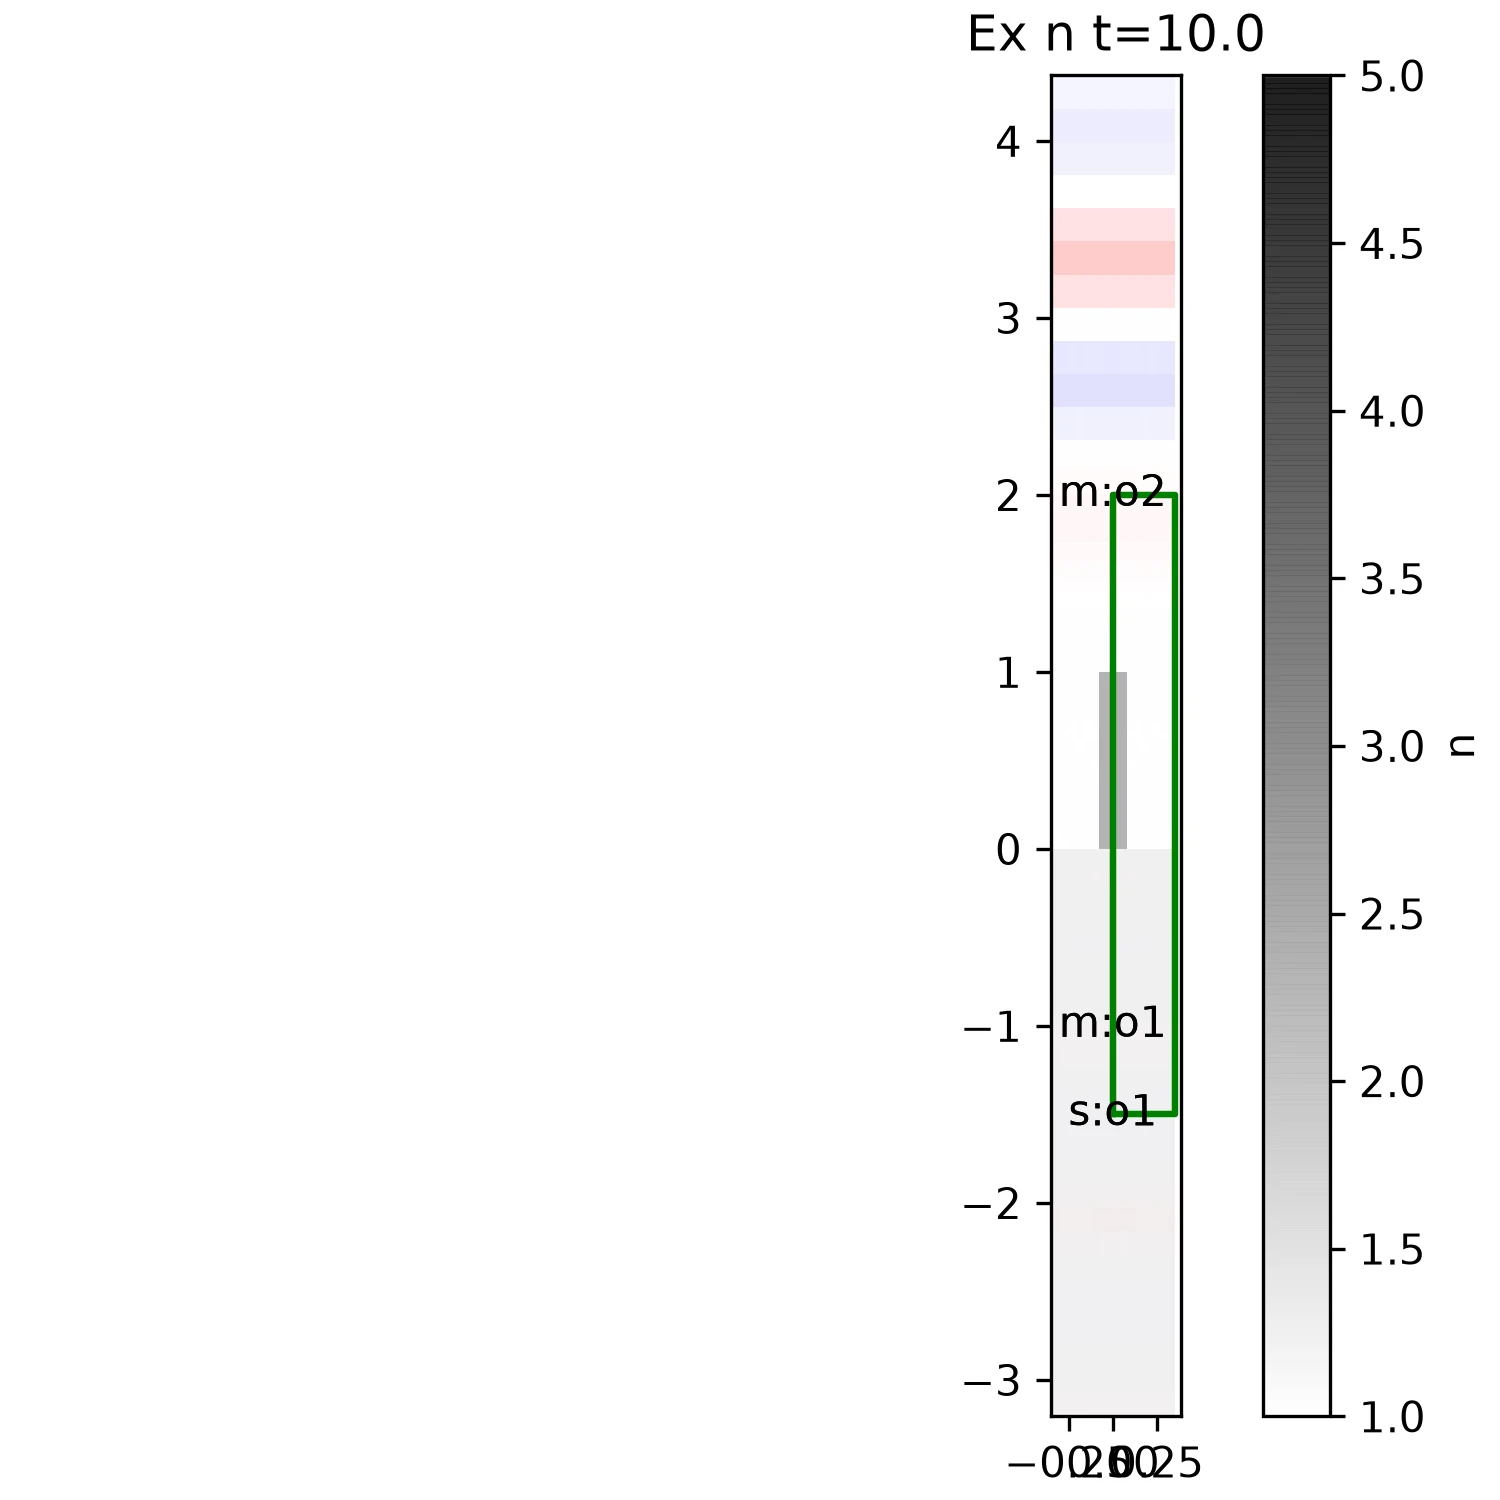

In [3]:
lumi.movie(paths[0])

## Results: phase library

loading solution from runs/r0.080
may take a minute if simulation folder is remotely mounted
loading solution from runs/r0.124
may take a minute if simulation folder is remotely mounted
loading solution from runs/r0.168
may take a minute if simulation folder is remotely mounted
loading solution from runs/r0.212
may take a minute if simulation folder is remotely mounted
loading solution from runs/r0.256
may take a minute if simulation folder is remotely mounted
loading solution from runs/r0.300
may take a minute if simulation folder is remotely mounted
phase coverage: 2.85 rad (0.45 x 2pi)


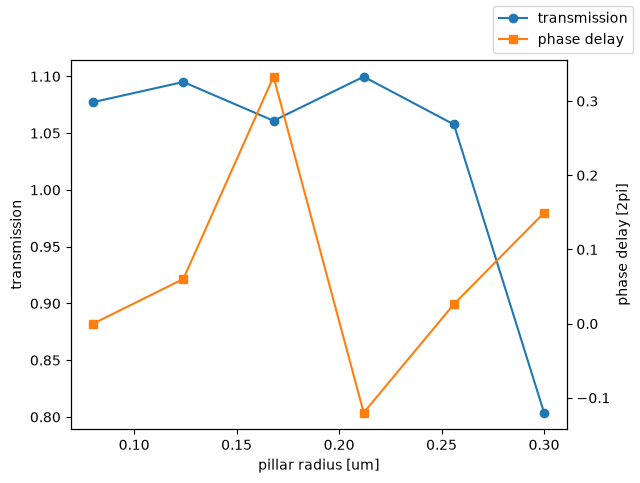

In [4]:
# S21 at center wavelength for each radius
mid = nwls // 2
S21 = []
for path in paths:
    sol = lumi.load(path)
    o1 = sol["monitors"]["o1"]
    o2 = sol["monitors"]["o2"]
    # + denotes outgoing mode (wrt port monitor outward normal), - incoming
    S21.append((o2["modes"][0]["+"] / o1["modes"][0]["-"])[mid])
S21 = np.array(S21)

# transmission relative to smallest pillar, oriented so larger pillars mean more phase delay
t = S21 / S21[0]
if np.unwrap(np.angle(t))[-1] < 0:
    t = np.conj(t)
delay = np.unwrap(np.angle(t))
print(f"phase coverage: {delay.max() - delay.min():.2f} rad ({(delay.max() - delay.min()) / (2 * np.pi):.2f} x 2pi)")

fig, ax = plt.subplots()
ax.plot(radii, np.abs(S21) ** 2, "o-", label="transmission")
ax.set_xlabel("pillar radius [um]")
ax.set_ylabel("transmission")
ax2 = ax.twinx()
ax2.plot(radii, delay / (2 * np.pi), "s-", color="C1", label="phase delay")
ax2.set_ylabel("phase delay [2pi]")
fig.legend()
plt.show()

## Metalens layout
Hyperbolic phase profile focuses normally incident light at focal length `f`. At each lattice site, pick the pillar whose complex transmission best matches the target

PosixPath('runs/metalens.gds')

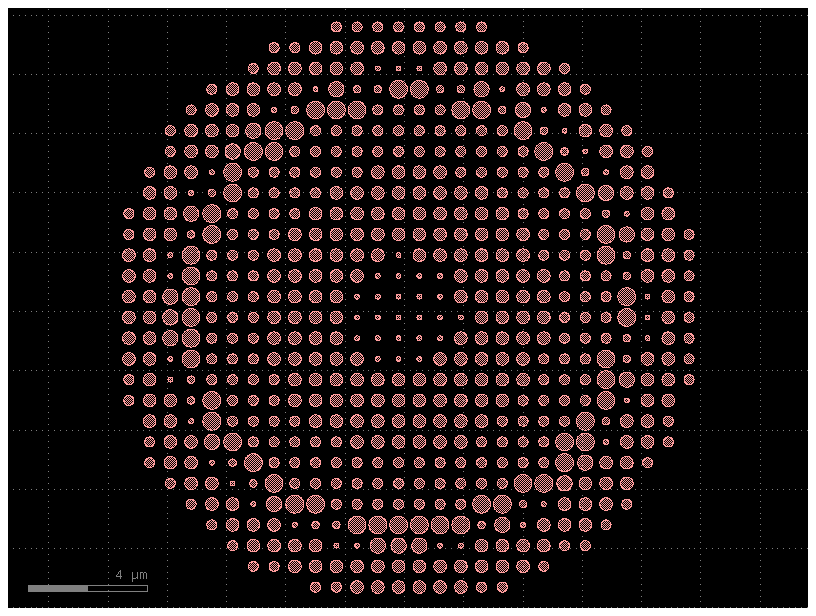

In [5]:
D = 20  # lens diameter [um]
f = 20  # focal length [um]

# library transmission normalized to max amplitude
lib = t * np.abs(S21) / np.abs(S21).max()

PILLAR = 1, 0
lens = gf.Component()
xs = np.arange(-D / 2, D / 2 + P / 2, P)
for x in xs:
    for y in xs:
        rho = np.hypot(x, y)
        if rho > D / 2:
            continue
        # center delayed most: edge rays travel farther to focus
        target = np.exp(-1j * 2 * np.pi / wavelength * (np.hypot(rho, f) - f))
        r = radii[np.argmin(np.abs(lib - target))]
        tt = np.linspace(0, 2 * np.pi, 64, endpoint=False)
        lens.add_polygon(list(zip(x + r * np.cos(tt), y + r * np.sin(tt))), layer=PILLAR)

lens.plot()
lens.write_gds(os.path.join(root, "metalens.gds"))